# Artificial sources 
Make "fake" PNe for completeness tests.

In [1]:
# import packages
import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling import models
import astropy.visualization as vis
import astropy.coordinates as coords
import astropy.units as u
from astropy.stats import sigma_clipped_stats
from astropy.io import fits, ascii
from astropy.table import Table
#from astroquery.simbad import Simbad
import idlwrap
#import scipy
#from scipy import integrate
import random
from scipy import interpolate, integrate
from scipy.integrate import simps

In [ ]:
onecolumn = (8.8*u.cm).to(u.imperial.inch).value
twocolumn = (18.*u.cm).to(u.imperial.inch).value
goldenratio = 0.5*(1.+np.sqrt(5.))

In [ ]:
# OIII image
OIII_flux = fits.open('/home/jhartke/SIGNALS/data/M101/extracted_laval/M101F1-OIII5007flux.fits')
wcs_oiii = WCS(OIII_flux[0].header)


### Modelling a Ciardullo-like PNLF
Based on idl routines from Alessia Longobardi & Magda Arnaboldi, translated to python by Ana Ennis.


In [5]:


# version of idl function used to interpolate

def idl_tabulate(x, f, p=5) :
    def newton_cotes(x, f) :
        if x.shape[0] < 2 :
            return 0
        rn = (x.shape[0] - 1) * (x - x[0]) / (x[-1] - x[0])
        weights = integrate.newton_cotes(rn)[0]
        return (x[-1] - x[0]) / (x.shape[0] - 1) * np.dot(weights, f)
    ret = 0
    for idx in range(0, x.shape[0], p - 1) :
        ret += newton_cotes(x[idx:idx + p], f[idx:idx + p])
    return ret


# first we generate a list of positions and magnitudes considering the shape of the luminosity function
# JHa: leaving the option to do this exercise for multiple slices, but setting sli=1 for now
# Same for wv0 and sigma that describe the velocity dispersion of the galaxy
# added: rotate=False, as some coordinate rotation is applied in the code that is not necessary here

def generate_random(num, magmin, magmax, xpix, ypix, path='C:/Users/ennis/Documents/Work/2023/pne/m105/completeness/', 
                    sli=14, wv0=None, sigma=None, show=True, rotate=False):
    
# consider the velocity dispersion
    if wv0 != None and sigma != None:
        mu, sigma = wv0, sigma # mean and standard deviation
        s = np.random.normal(mu, sigma, num*sli)

        if show == True:
            count, bins, ignored = plt.hist(s, 20, density=True)
            plt.plot(bins, 1/(sigma * np.sqrt(2 * np.pi)) *
                    np.exp( - (bins - mu)**2 / (2 * sigma**2) ),
                        linewidth=2, color='k')
            plt.vlines(5029.5,0,0.04,color='k')
            plt.show()

            
    for p in range(1,sli+1):
# parameters: num, maximum amount of sources per slice
#             magmin,magmax, self explanatorry

        num = num
        magmin = magmin
        magmax = magmax
    
# we establish the shape of the lumfunc (Ciardullo luminosity function)
        lumf = idlwrap.fltarr(2,100)
        for i in range(100):
            lumf[:,0][i] = magmin +((magmax-magmin)/100)*i
            lumf[:,1][i] = np.exp(0.307*lumf[:,0][i])*(1-np.exp(3*(magmin-lumf[:,0][i])))
        
        lumf[:,1] = lumf[:,1] + np.abs(lumf[1,0])
            
# we interpolate

        result = idl_tabulate(lumf[:,0],lumf[:,1])
        lumf[:,1] = (num/result)*lumf[:,1]
        
        area = idl_tabulate(lumf[:,0],lumf[:,1])
            
            
# check
        
        if show == True:
            plt.title('Ciardullo (1989) Luminosity function (input)')
            plt.plot(lumf[:,0],lumf[:,1])
            plt.xlabel('$m_{5007}$')
            plt.ylabel('$N_{PN}$')
            plt.show()

# create sources in bins

        nbin = 18
        dm = (magmax-magmin)/nbin

        cmag = idlwrap.fltarr(nbin)
        numpar = idlwrap.fltarr(nbin)
            
        cmag[0] = magmin+dm/2

        for i in range(1,nbin):
            cmag[i] = cmag[i-1]+dm

        for i in range(nbin):
            l = 0
            while(lumf[:,0][l]<=cmag[i]):
                l = l+1
            numero = random.random()
    
            if (numero>0.5):
                u = 1
            if (numero<=0.5):
                u = -1
        
            numpar[i] = int(((lumf[:,1][l-1]+lumf[:,1][l])/2)*dm)
            
            
        
        if show == True:
            plt.title('Binned PNLF')
            plt.xlabel('$m_{5007}$')
            plt.ylabel('$N_{PN}$')
            plt.bar(cmag,numpar,width=dm, edgecolor='w', linewidth=2)
            plt.show()        
        
        ocubin = idlwrap.fltarr(nbin)
        cc = 0

        for i in range(nbin):
            cc = cc+numpar[i]
            
        if(cc<num):
            for i in range(int(num-cc)):
                random.seed(10)
                numero = int(random.random()*nbin)
                numpar[numero]=numpar[numero]+1
        num = cc
        magnipar = idlwrap.fltarr(num)

        
        if show == True:
            plt.title('Binned PNLF (logarithmic)')
            plt.xlabel('$m_{5007}$')
            plt.ylabel('$\log_{10} N_{PN}$')
            plt.bar(cmag,np.log10(numpar), width=dm, edgecolor='w', linewidth=2)
            plt.show()
       
        a = idlwrap.fltarr(3,num)
        aa = idlwrap.fltarr(3,num)

        i = 0
        for i in range(int(num)):
            l = 0
            for j in range(nbin):
                if(ocubin[j]<numpar[j]):
                    l = l+1
            ind = idlwrap.fltarr(l)
            for ii in range(l):
                for j in range(nbin):
                    if(ocubin[j]<numpar[j]):
                        ind[ii] = j
            num1 = int(random.random()*l)

            j = int(ind[num1])
            ocubin[j] = ocubin[j] + 1

            numero = random.random()
            if (numero<0.5):
                magnipar[i] = random.random()*(dm/2)+cmag[j]
            if(numero>0.5):
                magnipar[i] = cmag[j] - random.random()*(dm/2)
            a[:,2][i] = magnipar[i]

            
        random.seed(10)
        num1 = int(random.random()*l)
        j = int(ind[num1])
        ocubin[j] = ocubin[j] + 1

        numero = random.random()
        if (numero<0.5):
            magnipar[i] = random.random()*(dm/2)+cmag[j]
        if(numero>0.5):
            magnipar[i] = cmag[j] - random.random()*(dm/2)
            
# assign coordinates to the magnitudes
            
        x_pix = xpix
        y_pix = ypix

        b = idlwrap.fltarr(2,num)
        for i in range(int(num)):
            a[:,0][i] = x_pix * random.random()# + 15
            a[:,1][i] = y_pix * random.random()# + 15
            b[:,0][i] = (a[:,0][i]*np.cos(-0.6)-a[:,1][i]*np.sin(-0.6))
            b[:,1][i] = (a[:,1][i]*np.cos(-0.6)+a[:,0][i]*np.sin(-0.6))+170

        
        if show == True:
            sc=plt.scatter(a[:,0],a[:,1], s=3, c=a[:,2], vmin=magmin, vmax=magmax)
            plt.title('Distribution on Detector')
            plt.xlabel("X [pix]")
            plt.ylabel("Y [pix]")
            cb=plt.colorbar(sc)
            cb.set_label('$m_{5007}$')
            plt.show()

#         binw = int((magmax-magmin)/dm)-1
#         result2 = np.histogram(magnipar,bins=binw,range=(magmin,magmax))
        
#         if show == True:
#             plt.plot(cmag,result2[1])
#             plt.show()
#             plt.plot(lumf[:,0],np.log10(lumf[:,1]*dm))
#             plt.show()
        if rotate==True: numbers = np.column_stack((b[:,0],b[:,1],a[:,2]))
        else: numbers = np.column_stack((a[:,0],a[:,1],a[:,2]))
                
        # matching with the velocity dispersion
        if wv0 != None and sigma != None:
            wv = (wv0-sli/2)+(1.25*p-1)

            indexes = np.where((s>wv)&(s<wv+1.25))
            ar = s[indexes]

            mg = np.array([[0,0,0,0]])
            for j in range(len(ar)):
                random.shuffle(numbers[:,2])
                element = np.array([[numbers[:,0][j],numbers[:,1][j],numbers[:,2][j],ar[j]]])
                mg = np.concatenate((mg,element),axis=0)
            mg = np.delete(mg,(0),axis=0)
            
        mg = numbers

        filename = 'cat_{}.dat'.format(p)
        #np.savetxt(path+filename,mg)
        # JHa: save as ascii astropy table instead
        tab = Table(data=[mg[:,0], mg[:,1], mg[:,2]], names=('x_0', 'y_0', 'mag'))
        tab.write(path+filename, format='ascii')
        
        return tab

In [3]:
# what bright cut-off do we expect for M101? 
D = 10.23 * u.Mpc #(NED)
mu=5.*np.log10(D/(1.*u.pc))-5
print('Distance modulus: ', mu)
mstar = mu - 4.51
print('Apparent bright cutoff: ', mstar)

Distance modulus:  30.0493781685608
Apparent bright cutoff:  25.539378168560802


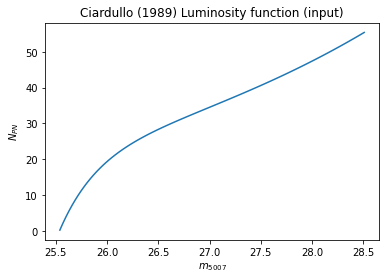

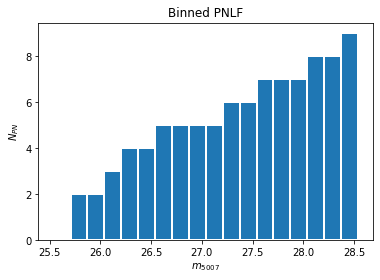

c:\users\ennis\anaconda3\envs\py36\lib\site-packages\ipykernel_launcher.py:125: RuntimeWarning: divide by zero encountered in log10


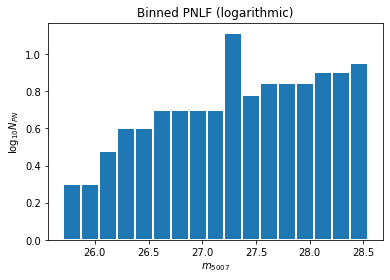

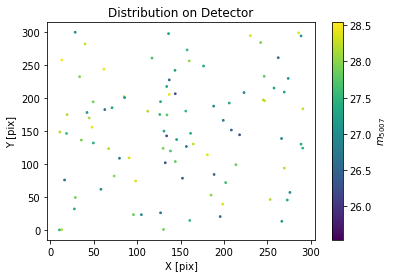

In [4]:
tab = generate_random(num=100, magmin=mstar, magmax=mstar+3, xpix=300, ypix=300) 

In [ ]:
# get noise parameters of [OIII] image
mean, median, std = sigma_clipped_stats(OIII_flux[0].data, sigma=3.0)
print('mean, median, std')
print(mean, median, std)

### PSF parameters determined in PSF+cross_matching notebook:
Moffat function with gamma = 3.0 pixels (core width) and alpha = 2.45 (outer slope, commonly known as beta):
$$f_\mathrm{Moffat}(r) = \left(1 + \frac{r^2}{\gamma^2}\right)^{-\alpha}$$
The normalisation is chosen such that $2\pi \int_{-\infty}^{\infty} f_\mathrm{Moffat}(r) r \mathrm{d}r = 1$. 
The half light radius ($f_\mathrm{Moffat}(r_h) = 0.5$) is $r_h = \gamma \sqrt{\sqrt[\alpha]{2} - 1}$.

In [ ]:
# make mock image with the same noise characteristics as [OIII] cutout
from photutils.datasets import (make_model_sources_image,
                                make_noise_image)

# we know the shape of the psf
model = models.Moffat2D(gamma=3, alpha=2.45)
n_sources = len(tab['x_0'])
shape = (250, 250)

# noise image with parameters from [OIII] flux map
noise = make_noise_image(shape, distribution='gaussian', mean=mean,
                         stddev=std)

# convert magnitudes to fluxes (Jacoby 1989):
normalisation = (np.pi*model.gamma**2/(model.alpha-1.))
tab['amplitude'] = 10**(-0.4*(tab['mag'] + 13.74))/normalisation
sources = tab['x_0', 'y_0', 'amplitude']

stars = make_model_sources_image(shape, model, sources)



In [ ]:
fig = plt.figure(figsize=(twocolumn, onecolumn/goldenratio))

norm = vis.simple_norm(stars+noise, 'linear', percent=95.)
ax1 = fig.add_subplot(131, aspect='equal')
ax1.imshow(noise, norm=norm)
ax1.set_title('Noise')

ax2 = fig.add_subplot(132, aspect='equal')
ax2.imshow(stars, norm=norm)
ax2.set_title('Simulated PNe')

ax3 = fig.add_subplot(133, aspect='equal')
ax3.imshow(stars + noise, norm=norm)
ax3.set_title('Simulated PNe + Noise')

fig.savefig('figures/test_images.png')